In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt

simulator = AerSimulator()
shots = 100

print("Qiskit Fall Fest 2026")
print("Challenge 2: Make the Quantum Coin Biased")
print("Simulator initialized successfully!")

Qiskit Fall Fest 2026
Challenge 2: Make the Quantum Coin Biased
Simulator initialized successfully!


In [2]:
experiments = {
    "Circuit A - Bias toward 0": np.pi / 3,
    "Circuit B - Bias toward 1": 2 * np.pi / 3,
    "Circuit C - Strong bias toward 0": np.pi / 6
}

predictions = {}

print("PREDICTIONS BEFORE EXECUTION")
print("=" * 60)

for name, theta in experiments.items():

    p0 = np.cos(theta / 2) ** 2
    p1 = np.sin(theta / 2) ** 2

    predictions[name] = {
        "0": p0,
        "1": p1
    }

    print(f"\n{name}")
    print(f"Predicted P(0): {p0 * 100:.2f}%")
    print(f"Predicted P(1): {p1 * 100:.2f}%")

PREDICTIONS BEFORE EXECUTION

Circuit A - Bias toward 0
Predicted P(0): 75.00%
Predicted P(1): 25.00%

Circuit B - Bias toward 1
Predicted P(0): 25.00%
Predicted P(1): 75.00%

Circuit C - Strong bias toward 0
Predicted P(0): 93.30%
Predicted P(1): 6.70%


Circuit A: Bias toward 0


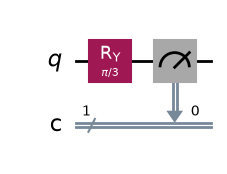

In [3]:
circuit_a = QuantumCircuit(1, 1)

circuit_a.ry(np.pi / 3, 0)
circuit_a.measure(0, 0)

print("Circuit A: Bias toward 0")
display(circuit_a.draw("mpl"))

Circuit B: Bias toward 1


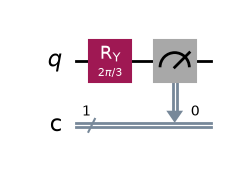

In [4]:
circuit_b = QuantumCircuit(1, 1)

circuit_b.ry(2 * np.pi / 3, 0)
circuit_b.measure(0, 0)

print("Circuit B: Bias toward 1")
display(circuit_b.draw("mpl"))

Circuit C: Strong Bias toward 0


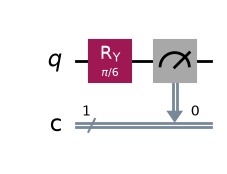

In [5]:
circuit_c = QuantumCircuit(1, 1)

circuit_c.ry(np.pi / 6, 0)
circuit_c.measure(0, 0)

print("Circuit C: Strong Bias toward 0")
display(circuit_c.draw("mpl"))

In [6]:
circuits = {
    "Circuit A - Bias toward 0": circuit_a,
    "Circuit B - Bias toward 1": circuit_b,
    "Circuit C - Strong bias toward 0": circuit_c
}

results = {}

for name, circuit in circuits.items():

    compiled = transpile(circuit, simulator)

    job = simulator.run(compiled, shots=shots)

    counts = job.result().get_counts()

    results[name] = counts

    print(f"{name}: {counts}")

print("\nAll three circuits executed successfully!")

Circuit A - Bias toward 0: {'0': 79, '1': 21}
Circuit B - Bias toward 1: {'0': 21, '1': 79}
Circuit C - Strong bias toward 0: {'0': 93, '1': 7}

All three circuits executed successfully!


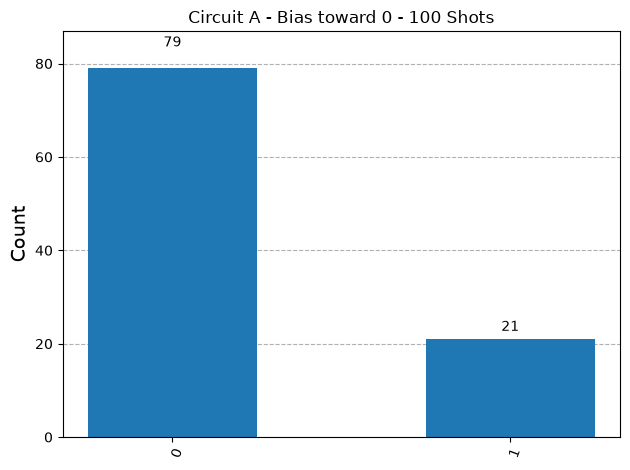

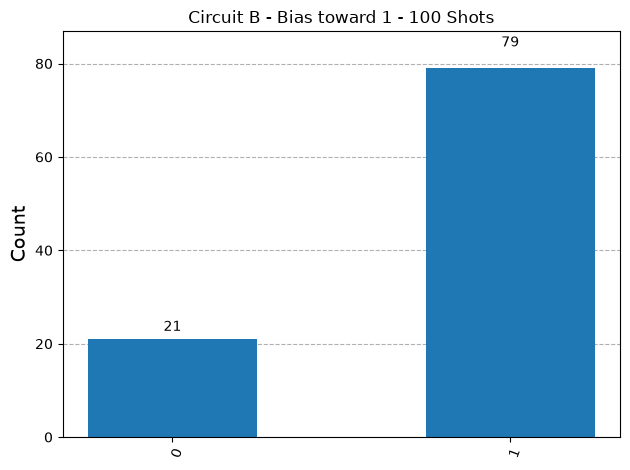

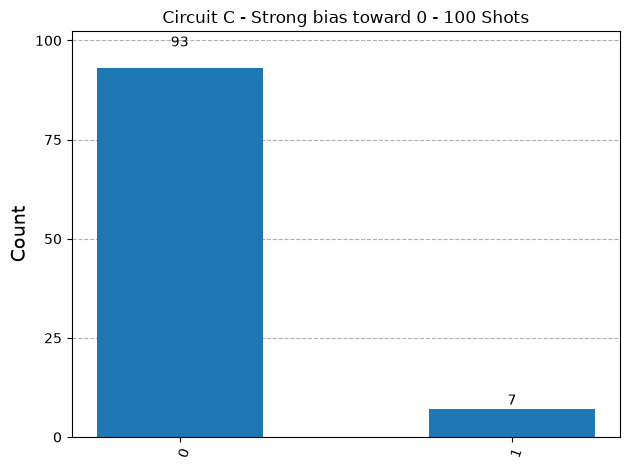

In [7]:
for name, counts in results.items():

    display(
        plot_histogram(
            counts,
            title=f"{name} - 100 Shots",
            bar_labels=True
        )
    )

In [8]:
print("PREDICTION VS ACTUAL RESULTS")
print("=" * 90)

print(
    f"{'Circuit':<38}"
    f"{'Predicted 0':<15}"
    f"{'Predicted 1':<15}"
    f"{'Actual 0':<12}"
    f"{'Actual 1':<12}"
)

print("-" * 90)

for name in circuits:

    pred = predictions[name]
    actual = results[name]

    print(
        f"{name:<38}"
        f"{pred['0'] * 100:<15.2f}"
        f"{pred['1'] * 100:<15.2f}"
        f"{actual.get('0', 0):<12}"
        f"{actual.get('1', 0):<12}"
    )

PREDICTION VS ACTUAL RESULTS
Circuit                               Predicted 0    Predicted 1    Actual 0    Actual 1    
------------------------------------------------------------------------------------------
Circuit A - Bias toward 0             75.00          25.00          79          21          
Circuit B - Bias toward 1             25.00          75.00          21          79          
Circuit C - Strong bias toward 0      93.30          6.70           93          7           


In [9]:
print("CHALLENGE 2 VALIDATION")
print("=" * 55)

for name, circuit in circuits.items():

    assert circuit.num_qubits == 1, f"{name}: Incorrect qubit count"
    assert circuit.num_clbits == 1, f"{name}: Missing classical bit"

    operations = circuit.count_ops()

    assert operations.get("measure", 0) == 1
    assert operations.get("ry", 0) <= 4

    assert sum(results[name].values()) == 100

    print(f"PASS: {name}")

print("\nAll circuit constraints validated successfully!")

print("\nObserved bias:")
for name, counts in results.items():
    p0 = counts.get("0", 0)
    p1 = counts.get("1", 0)

    print(f"{name}: 0 = {p0}%, 1 = {p1}%")

CHALLENGE 2 VALIDATION
PASS: Circuit A - Bias toward 0
PASS: Circuit B - Bias toward 1
PASS: Circuit C - Strong bias toward 0

All circuit constraints validated successfully!

Observed bias:
Circuit A - Bias toward 0: 0 = 79%, 1 = 21%
Circuit B - Bias toward 1: 0 = 21%, 1 = 79%
Circuit C - Strong bias toward 0: 0 = 93%, 1 = 7%


## Challenge 2 — Results and Conclusion

Three single-qubit circuits were designed using different RY rotation angles to create biased quantum measurement distributions. Each circuit was executed for 100 shots using the Qiskit Aer simulator.

Circuit A used an RY(π/3) gate to produce theoretical probabilities of 75% for state 0 and 25% for state 1.

Circuit B used an RY(2π/3) gate to reverse the bias, producing theoretical probabilities of 25% for state 0 and 75% for state 1.

Circuit C used an RY(π/6) gate to produce a stronger bias toward state 0, with theoretical probabilities of approximately 93.3% and 6.7%.

The measurement results can be compared with the predicted probabilities. Small differences are expected because only 100 shots are used.

Conclusion: The experiment demonstrates that changing the rotation angle of a quantum gate changes the probability amplitudes of the qubit. This allows us to control the likelihood of measuring 0 or 1 without determining the outcome of any individual measurement.

## Challenge Question — Answer

Quantum gates change the probability of obtaining 0 or 1 by modifying the probability amplitudes of a qubit's quantum state.

For example, the Hadamard gate creates an equal superposition, giving a 50% probability of measuring either 0 or 1. The RY rotation gate allows us to create unequal probabilities by changing the rotation angle.

For an RY(θ) gate applied to the initial state \(|0\rangle\), the probability of measuring 0 is cos²(θ/2), while the probability of measuring 1 is sin²(θ/2).

Therefore, by choosing different rotation angles, we can control the measurement probability distribution. However, the result of an individual quantum measurement remains probabilistic.